# CS156 — Linear Algebra and Multivariate Linear Regression

This session connected linear algebra to multiple linear regression. I used the Titanic dataset to predict passenger fare from three variables: passenger class (`Pclass`), age (`Age`), and number of siblings or spouses aboard (`SibSp`).

The predictors form the columns of the matrix $X$. Linear regression combines these predictors using a vector of coefficients $\beta$ to create predictions:

$$
\hat{y} = X\beta
$$

Here, $\hat{y}$ represents the predicted values, $X$ contains the predictor variables, and $\beta$ contains the coefficients learned by the model.

The difference between the actual value $y$ and the prediction $\hat{y}$ is called the **residual**:

$$
e = y - \hat{y}
$$

Ordinary Least Squares (OLS) finds the coefficients that make these residuals as small as possible by minimizing their squared values.

# Question 1 of 5 — Code Prep

## Predicting Passenger Fare with Multiple Linear Regression

The question asks me to create a dataframe where **Fare** is the dependent variable and three other variables are used as predictors.

I selected:

- `Pclass` — passenger ticket class
- `Age` — passenger age in years
- `SibSp` — number of siblings or spouses aboard
- `Fare` — passenger fare; this is the target variable

The model can be written as:

$$
Fare_i = \beta_0 + \beta_1Pclass_i + \beta_2Age_i + \beta_3SibSp_i + \epsilon_i
$$

Here, $\beta_0$ is the intercept, while $\beta_1$, $\beta_2$, and $\beta_3$ describe how each predictor contributes to the predicted fare.

I remove rows with missing values because `Age` is missing for some passengers. This reduces the number of observations, but the structure of the regression model stays the same.

I also use an 80/20 train-test split. This was not strictly required, but it lets me evaluate the model on passengers that were not used during training.

In [4]:
# Loading libraries
import pandas as pd
import requests
from io import StringIO
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Loading the Titanic dataset
file_id = "1Uzux8-5IzQOr-l7-zCONShsAvzP4JgTA"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

response = requests.get(url)
response.raise_for_status()

titanic_df = pd.read_csv(StringIO(response.text))

# Inspecting the dataset
display(titanic_df.head())
print(titanic_df.columns)

# Keeping the target and three predictors, then removing incomplete rows
df = titanic_df[["Fare", "Pclass", "Age", "SibSp"]].dropna()

# Separating predictors from the target
X = df[["Pclass", "Age", "SibSp"]]
y = df["Fare"]

# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fitting the multiple linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predicting fares for the test set
y_pred = model.predict(X_test)

# Evaluating the model
mse = mean_squared_error(y_test, y_pred)
r2 = model.score(X_test, y_test)

# Displaying the fitted model
print("Intercept:", model.intercept_)
print("Pclass coefficient:", model.coef_[0])
print("Age coefficient:", model.coef_[1])
print("SibSp coefficient:", model.coef_[2])
print("Mean Squared Error:", mse)
print("R-squared:", r2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')
Intercept: 120.20432881478297
Pclass coefficient: -37.347203360034285
Age coefficient: -0.24047530260421446
SibSp coefficient: 10.537879131988381
Mean Squared Error: 3388.1492554957017
R-squared: 0.18618448729472836


## Interpretation of the Regression Model

The fitted coefficients show how each predictor is related to passenger fare while the other variables are held constant.

In my result, `Pclass` had the largest coefficient in magnitude. Since `Pclass = 1` represents first class and `Pclass = 3` represents third class, its negative coefficient makes sense; moving toward a lower ticket class is associated with a lower predicted fare.

The test $R^2$ was about $0.19$. This means that `Pclass`, `Age`, and `SibSp` explain some, but not all, of the variation in passenger fares.

# Question 2 of 5 — Core Questions

## Writing the Regression Model in Matrix Form

The sklearn model uses three predictors and also includes an intercept. Therefore, the full design matrix $X$ has four columns:

$$
X =
\begin{bmatrix}
1 & Pclass_1 & Age_1 & SibSp_1 \\
1 & Pclass_2 & Age_2 & SibSp_2 \\
\vdots & \vdots & \vdots & \vdots \\
1 & Pclass_n & Age_n & SibSp_n
\end{bmatrix}
$$

The coefficient vector is:

$$
\beta =
\begin{bmatrix}
\beta_0 \\
\beta_1 \\
\beta_2 \\
\beta_3
\end{bmatrix}
$$

The target vector contains the observed passenger fares:

$$
Y =
\begin{bmatrix}
Fare_1 \\
Fare_2 \\
\vdots \\
Fare_n
\end{bmatrix}
$$

The full regression model is:

$$
Y = X\beta + \epsilon
$$

and the predicted values are:

$$
\hat{Y} = X\beta
$$

The columns of $X$ define the directions that the model can combine. All possible prediction vectors therefore lie inside the **column space of $X$**.

## Ordinary Least Squares Loss Function

The residual vector measures the difference between the actual and predicted values:

$$
e = Y - X\beta
$$

Ordinary Least Squares minimizes the Sum of Squared Residuals:

$$
L(\beta) = (Y-X\beta)^T(Y-X\beta)
$$

Expanding this gives:

$$
L(\beta) = Y^TY - 2\beta^TX^TY + \beta^TX^TX\beta
$$

The goal is to find the values of $\beta$ that make this loss as small as possible.

## Differentiating the OLS Loss

To find the minimum of the loss function, I differentiate it with respect to the coefficient vector $\beta$:

$$
\nabla_{\beta}L = 2X^TX\beta - 2X^TY
$$

At the minimum, the gradient is zero:

$$
2X^TX\beta - 2X^TY = 0
$$

Dividing by $2$ gives:

$$
X^TX\beta = X^TY
$$

This is the **normal equation**.

If $X^TX$ is invertible, I can solve for the coefficients:

$$
\hat{\beta} = (X^TX)^{-1}X^TY
$$

Geometrically, this chooses the prediction vector $\hat{Y}$ in the column space of $X$ that is closest to the actual vector $Y$.

## Three-Point Numerical Example

The assignment asks for a $3\times3$ matrix using the three predictors. This is slightly different from the sklearn model because sklearn includes an intercept.

For this numerical example only, I therefore use a **no-intercept model**.

The three observations give:

$$
X =
\begin{bmatrix}
3 & 22 & 1 \\
1 & 38 & 1 \\
3 & 26 & 0
\end{bmatrix}
$$

and:

$$
Y =
\begin{bmatrix}
7.25 \\
71.2833 \\
7.925
\end{bmatrix}
$$

The fitted coefficient vector is approximately:

$$
\hat{\beta} =
\begin{bmatrix}
-15.380658 \\
2.079499 \\
7.642996
\end{bmatrix}
$$

Because this $3\times3$ matrix is invertible, the three coefficients can reproduce the three observations exactly:

$$
X\hat{\beta} = Y
$$

Therefore:

$$
e = Y-X\hat{\beta} = 0
$$

This example is mainly a linear algebra demonstration. Its coefficients should not be expected to match the coefficients learned from the full Titanic dataset.

# Question 3 of 5 — Core Questions

## Plotting the Data and the Fitted Regression Model

The full regression contains three predictors plus `Fare`, so the complete relationship exists in four dimensions. I cannot display all four dimensions directly in a normal 3D plot.

To make the model visible, I fix `SibSp = 0`. This leaves:

- x-axis — `Pclass`
- y-axis — `Age`
- z-axis — `Fare`

The fitted surface represents the fares predicted by the regression model, while the scatter points show actual passengers with `SibSp = 0`.

The vertical distance between an observed point and the fitted surface represents its residual.

# Question 4 of 5 — Extension Questions

## Visualizing the Three-Variable Regression Model

For this visualization, I fit the regression using the complete cleaned dataset.

The model has three predictors:

$$
\widehat{Fare} = \beta_0 + \beta_1Pclass + \beta_2Age + \beta_3SibSp
$$

Since I cannot show all three predictors and `Fare` at the same time in 3D, I hold `SibSp` constant at $0$.

The displayed surface is therefore one slice of the full regression hyperplane:

$$
\widehat{Fare} = \beta_0 + \beta_1Pclass + \beta_2Age + \beta_3(0)
$$

This lets me see how passenger class and age relate to predicted fare while keeping the third predictor fixed.

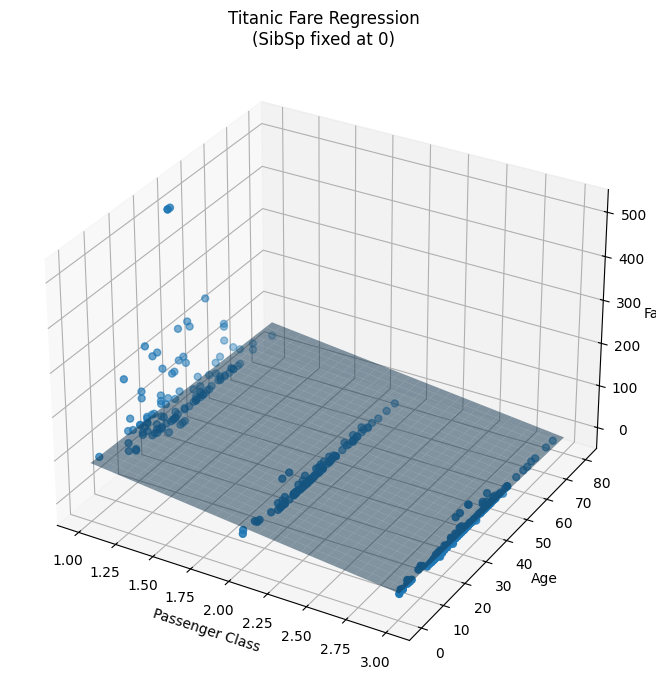

In [2]:
# Loading libraries for the visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Keeping the same predictors and target
df = titanic_df[["Pclass", "Age", "SibSp", "Fare"]].dropna()

# Separating predictors and target
X = df[["Pclass", "Age", "SibSp"]]
y = df["Fare"]

# Fitting the regression model using the full cleaned dataset
model = LinearRegression()
model.fit(X, y)

# Holding SibSp constant so the model can be shown in 3D
sibsp_fixed = 0

# Creating values across Pclass and Age
p_grid = np.linspace(1, 3, 30)
a_grid = np.linspace(df["Age"].min(), df["Age"].max(), 30)
P, A = np.meshgrid(p_grid, a_grid)

# Creating predictor combinations for the regression surface
grid = pd.DataFrame({"Pclass": P.ravel(), "Age": A.ravel(), "SibSp": sibsp_fixed})

# Predicting Fare for each point on the grid
Z = model.predict(grid).reshape(P.shape)

# Keeping actual passengers from the same SibSp slice
plot_df = df[df["SibSp"] == sibsp_fixed]

# Creating the 3D visualization
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# Plotting the regression surface
ax.plot_surface(P, A, Z, alpha=0.5)

# Plotting the actual observations
ax.scatter(plot_df["Pclass"], plot_df["Age"], plot_df["Fare"], s=25)

# Labeling the axes
ax.set_xlabel("Passenger Class")
ax.set_ylabel("Age")
ax.set_zlabel("Fare")
ax.set_title("Titanic Fare Regression\n(SibSp fixed at 0)")

plt.tight_layout()
plt.show()

## Interpretation of the Visualization

The fitted surface represents predicted passenger fares when `SibSp = 0`.

Passenger class has a clear relationship with the model's predicted fares; first-class passengers generally have higher predicted fares than third-class passengers. Age changes the prediction more gradually.

The actual observations do not all lie directly on the fitted surface. The gap between an observed point and the surface represents prediction error, or the residual.

This helped me understand why multiple linear regression produces a plane or, with more predictors, a higher-dimensional **hyperplane** rather than a single regression line.

# Question 5 of 5 — Extension Questions

## 1. Sum of Squared Residuals

I chose the **Sum of Squared Residuals (SSR)** as my measure of model fit.

For each observation, the residual is:

$$
r_i = y_i-\hat{y}_i
$$

For all observations together:

$$
r = Y-\hat{Y}
$$

The Sum of Squared Residuals is:

$$
SSR = \sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

In vector notation:

$$
SSR = r^Tr
$$

Spatially, this is the **squared Euclidean length of the residual vector**. It measures the squared distance between the actual target vector $Y$ and its projection $\hat{Y}$ onto the column space of $X$.

A smaller SSR means that the model's predictions are closer to the observed values.

## 2. Calculate SSR by Hand for the Three Data Points

For the three-point, no-intercept example:

$$
\hat{\beta} =
[-15.380658,\ 2.079499,\ 7.642996]^T
$$

For passenger 1:

$$
\hat{y}_1 = 3(-15.380658) + 22(2.079499) + 1(7.642996) = 7.25
$$

For passenger 2:

$$
\hat{y}_2 = 1(-15.380658) + 38(2.079499) + 1(7.642996) = 71.2833
$$

For passenger 3:

$$
\hat{y}_3 = 3(-15.380658) + 26(2.079499) + 0(7.642996) = 7.925
$$

Therefore:

$$
\hat{Y} = Y
$$

and:

$$
r = Y-\hat{Y} = 0
$$

So:

$$
SSR = 0^2 + 0^2 + 0^2 = 0
$$

The SSR is zero because this simplified example contains three observations and three parameters, and the $3\times3$ matrix is invertible. The three-point system can therefore reproduce all three observations exactly.

## 3. Calculate SSR for the Full Dataset

For the full cleaned Titanic dataset, I fit the three-predictor regression with an intercept.

I calculate a prediction for every passenger, subtract each prediction from the actual fare, square each residual, and then add the squared residuals together.

This gives the in-sample SSR for the full cleaned dataset.

In [3]:
# Loading the required libraries
import numpy as np
from sklearn.linear_model import LinearRegression

# Creating the predictor matrix and target vector
X = df[["Pclass", "Age", "SibSp"]].to_numpy(dtype=float)
y = df["Fare"].to_numpy(dtype=float)

# Fitting the regression model with an intercept
model = LinearRegression()
model.fit(X, y)

# Predicting Fare for every passenger
y_pred = model.predict(X)

# Calculating residuals
residuals = y - y_pred

# Calculating the Sum of Squared Residuals
SSR = np.sum(residuals ** 2)

print("Sum of Squared Residuals:", SSR)

Sum of Squared Residuals: 1312882.8385698097


## Interpretation of the Full-Dataset SSR

The full-dataset SSR is much larger than the three-point SSR because the full model cannot pass exactly through every passenger observation.

This is expected. Real passenger fares vary for reasons that are not completely captured by `Pclass`, `Age`, and `SibSp`.

The SSR summarizes the total squared distance between the observed fares and the fares predicted by the regression model.

## 4. Differentiate the SSR with Respect to the Three Coefficients

For the three-point, no-intercept model, the loss function is:

$$
L(\beta) = (Y-X\beta)^T(Y-X\beta)
$$

where:

$$
\beta = [\beta_1,\ \beta_2,\ \beta_3]^T
$$

Expanding the loss gives:

$$
L(\beta) = Y^TY - 2\beta^TX^TY + \beta^TX^TX\beta
$$

Differentiating with respect to $\beta$ gives:

$$
\nabla_{\beta}L = -2X^TY + 2X^TX\beta
$$

Therefore:

$$
\nabla_{\beta}L = 2X^TX\beta - 2X^TY
$$

This can also be written as:

$$
\nabla_{\beta}L = -2X^T(Y-X\beta)
$$

## Applying the Derivative to the Three Titanic Observations

For the three observations:

$$
X^TX =
\begin{bmatrix}
19 & 182 & 4 \\
182 & 2604 & 60 \\
4 & 60 & 2
\end{bmatrix}
$$

and:

$$
X^TY =
\begin{bmatrix}
116.8083 \\
3074.3154 \\
78.5333
\end{bmatrix}
$$

The three partial derivatives are:

$$
\frac{\partial L}{\partial\beta_1}
=
2(19\beta_1 + 182\beta_2 + 4\beta_3 - 116.8083)
$$

$$
\frac{\partial L}{\partial\beta_2}
=
2(182\beta_1 + 2604\beta_2 + 60\beta_3 - 3074.3154)
$$

$$
\frac{\partial L}{\partial\beta_3}
=
2(4\beta_1 + 60\beta_2 + 2\beta_3 - 78.5333)
$$

At the fitted solution:

$$
\hat{\beta} = [-15.380658,\ 2.079499,\ 7.642996]^T
$$

the residuals are zero, so:

$$
\nabla_{\beta}L = [0,\ 0,\ 0]^T
$$

Spatially, this means there is no direction in coefficient space that can reduce the SSR any further. The loss is at its minimum.

# Final Session Takeaway

This session helped me connect multiple linear regression to the geometry of vector spaces.

The columns of $X$ define the directions available to the model. The coefficient vector $\beta$ determines how much of each direction is combined, producing the prediction:

$$
\hat{Y} = X\beta
$$

The residual is:

$$
e = Y-\hat{Y}
$$

and OLS minimizes:

$$
SSR = e^Te
$$

The main sequence I learned was:

**predictors → design matrix $X$ → column space → prediction $X\beta$ → residuals → SSR → derivative → minimum**

I also learned why collinearity matters. If the columns of $X$ become linearly dependent, then $X^TX$ can become singular and the ordinary inverse may not exist. If the columns are only nearly dependent, the coefficients can become unstable even though the model may still produce similar fitted values.